**«Исследование и сравнение методов понижения размерности и кластеризации на реальном высокоразмерном датасете (из области по выбору: биоинформатика, тексты, изображения, графы) с анализом устойчивости и интерпретируемости полученных кластеров»**

Основные требования к проекту:

1. Выбор и обоснование одного или двух реальных высокоразмерных датасетов (например, single‑cell RNA‑seq, embedding‑представления текстов, feature‑описания изображений).
2. Построение и сравнение нескольких пайплайнов «DR → кластеризация» (минимум 3 DR‑метода и 3 алгоритма кластеризации) с оценкой качества, устойчивости и практической интерпретации кластеров.

**Датасет UCI HAR**

**Распознавание активности человека с помощью смартфонов**

База данных по распознаванию активности человека, созданная на основе записей 30 испытуемых, выполнявших повседневные действия (ADL) со смартфоном на поясе, оснащенным встроенными инерциальными датчиками.

*Активности:*
* WALKING - ХОДЬБА
* WALKING_UPSTAIRS - ПОДЪЕМ ПО ЛЕСТНИЦЕ
* WALKING_DOWNSTAIRS - СПУСК ПО ЛЕСТНИЦЕ
* SITTING - СИДЕНИЕ
* STANDING - СТОЯНИЕ
* LAYING - ЛЕЖАНИЕ


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score, adjusted_mutual_info_score, v_measure_score

import umap.umap_ as umap
import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

Загрузка данных

In [22]:
df = fetch_openml(data_id=1478, as_frame=False, parser="liac-arff")

In [23]:
X = df.data.astype(np.float64)
y = df.target.astype(int)

y = y - 1

print("Размерность:", X.shape)
print("Классы:", np.unique(y))
print("Распределение классов:")
print((pd.Series(y).value_counts(normalize=True).sort_index() * 100).round(2).astype(str) + " %")

Размерность: (10299, 561)
Классы: [0 1 2 3 4 5]
Распределение классов:
0    16.72 %
1    14.99 %
2    13.65 %
3    17.25 %
4    18.51 %
5    18.88 %
Name: proportion, dtype: str


In [24]:
activity_names = [
    "walking",
    "walking_upstairs",
    "walking_downstairs",
    "sitting",
    "standing",
    "laying",
]

In [25]:
rng = np.random.RandomState(42)

rnd = []
for activity in np.unique(y):
    pool = np.flatnonzero(y == activity)
    rnd.append(rng.choice(pool, size=1000, replace=False))

rnd = np.concatenate(rnd)
rng.shuffle(rnd)

X_rnd = X[rnd]
y_rnd = y[rnd]

print("Размерность:", X_rnd.shape)
print(pd.Series(y_rnd).value_counts().sort_index())

Размерность: (6000, 561)
0    1000
1    1000
2    1000
3    1000
4    1000
5    1000
Name: count, dtype: int64


Стандартизация

In [26]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_rnd)

**DR-методы**

PCA

In [27]:
pca_model = PCA(n_components=2, random_state=42)
X_pca = pca_model.fit_transform(X_scaled)

t-SNE

In [28]:
tsne_model = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=42, n_jobs=-1)
X_tsne = tsne_model.fit_transform(X_scaled)

UMAP

In [29]:
umap_model = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=42)
X_umap = umap_model.fit_transform(X_scaled)

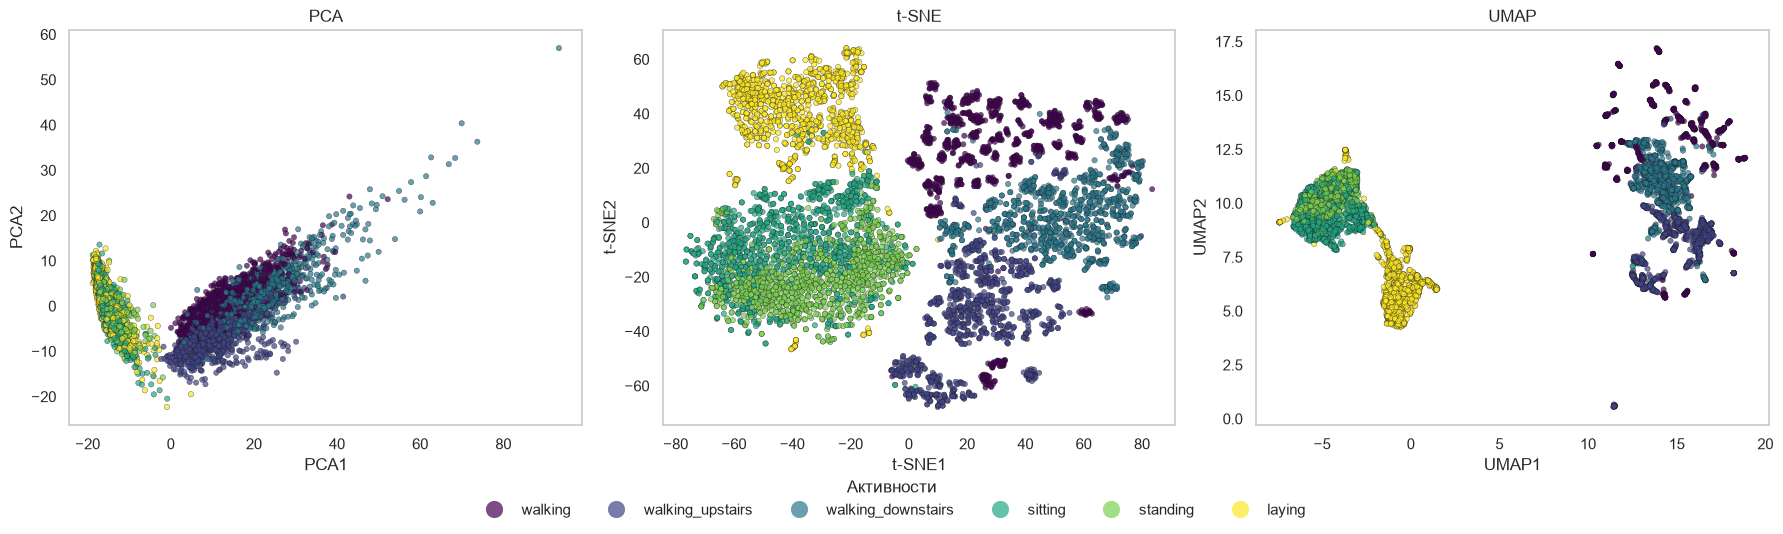

In [30]:
res = {"PCA": X_pca, "t-SNE": X_tsne, "UMAP": X_umap}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (title, res1) in enumerate(res.items()):
    scatter = axes[i].scatter(res1[:, 0], res1[:, 1], c=y_rnd,
                         cmap="viridis", alpha=0.7, s=15, edgecolors="k", linewidth=0.3 )
    axes[i].set_xlabel(f"{title}1")
    axes[i].set_ylabel(f"{title}2")
    axes[i].set_title(title)
    axes[i].grid(False)

handles, _ = scatter.legend_elements()
fig.legend(handles, activity_names, title="Активности",
           loc="lower center", bbox_to_anchor=(0.5, -0.08), ncol=6, frameon=False, markerscale=2)

plt.tight_layout()
plt.show()

**DR → кластеризация**

* KMeans
* AgglomerativeClustering
* GMM

In [31]:
k = 6
rows = []
all_pred = {}

methods = [
    ("KMeans", lambda: KMeans(n_clusters=k, random_state=42, n_init=10)),
    ("AgglomerativeClustering", lambda: AgglomerativeClustering(n_clusters=k)),
    ("GMM", lambda: GaussianMixture(n_components=k, random_state=42, n_init=5))
]

for dec, res1 in res.items():
    for alg_name, alg_factory in methods:
        
        model = alg_factory()
        labels = model.fit_predict(res1)

        all_pred[(dec, alg_name)] = labels
        
        rows.append({
            "dec": dec,
            "algorithm": alg_name,
            "silhouette": round(silhouette_score(res1, labels), 4),
            "calinski_harabasz": round(calinski_harabasz_score(res1, labels), 2),
            "davies_bouldin": round(davies_bouldin_score(res1, labels), 4),
            "ari": round(adjusted_rand_score(y_rnd, labels), 4),
            "ami": round(adjusted_mutual_info_score(y_rnd, labels), 4),
            "v_measure": round(v_measure_score(y_rnd, labels), 4),
        })

df = pd.DataFrame(rows)

df = df.sort_values("ari", ascending=False).reset_index(drop=True)
df

,dec,algorithm,silhouette,calinski_harabasz,davies_bouldin,ari,ami,v_measure
0,t-SNE,KMeans,0.4356,7538.30,0.8203,0.6163,0.7034,0.7038
1,UMAP,GMM,0.5514,40174.37,0.7824,0.6088,0.7245,0.7249
2,UMAP,AgglomerativeClustering,0.5307,37681.74,0.7629,0.6018,0.7319,0.7322
3,t-SNE,AgglomerativeClustering,0.3973,6752.67,0.8624,0.5848,0.6591,0.6595
4,t-SNE,GMM,0.4300,7286.04,0.8213,0.5765,0.6729,0.6733
5,UMAP,KMeans,0.5547,40792.70,0.7449,0.5608,0.6925,0.6928
6,PCA,AgglomerativeClustering,0.4623,16138.08,0.7271,0.2951,0.4615,0.4622
7,PCA,KMeans,0.4646,17721.74,0.7553,0.2784,0.4460,0.4466
8,PCA,GMM,0.3748,10315.12,1.1598,0.2784,0.4305,0.4312


UMAP доминирует по внутренним меркам: огромный calinski_harabasz (40 000 против 7 000 у остальных) и лучший silhouette (0.55). Кластеры плотные и далеко разнесены

t-SNE + KMeans хорошо выделил локальные группы (самый высокий ARI), но внутренние метрики значительно хуже (кластеры визуально размазаны)

РСА + GMM показал худщий результат по перекрытию, ARI на всех алгоритмах  упал до 0.28


Лучшие комбинации по качеству кластеров и геометрии:
1. UMAP	→ GMM	
2. UMAP	→ AgglomerativeClustering

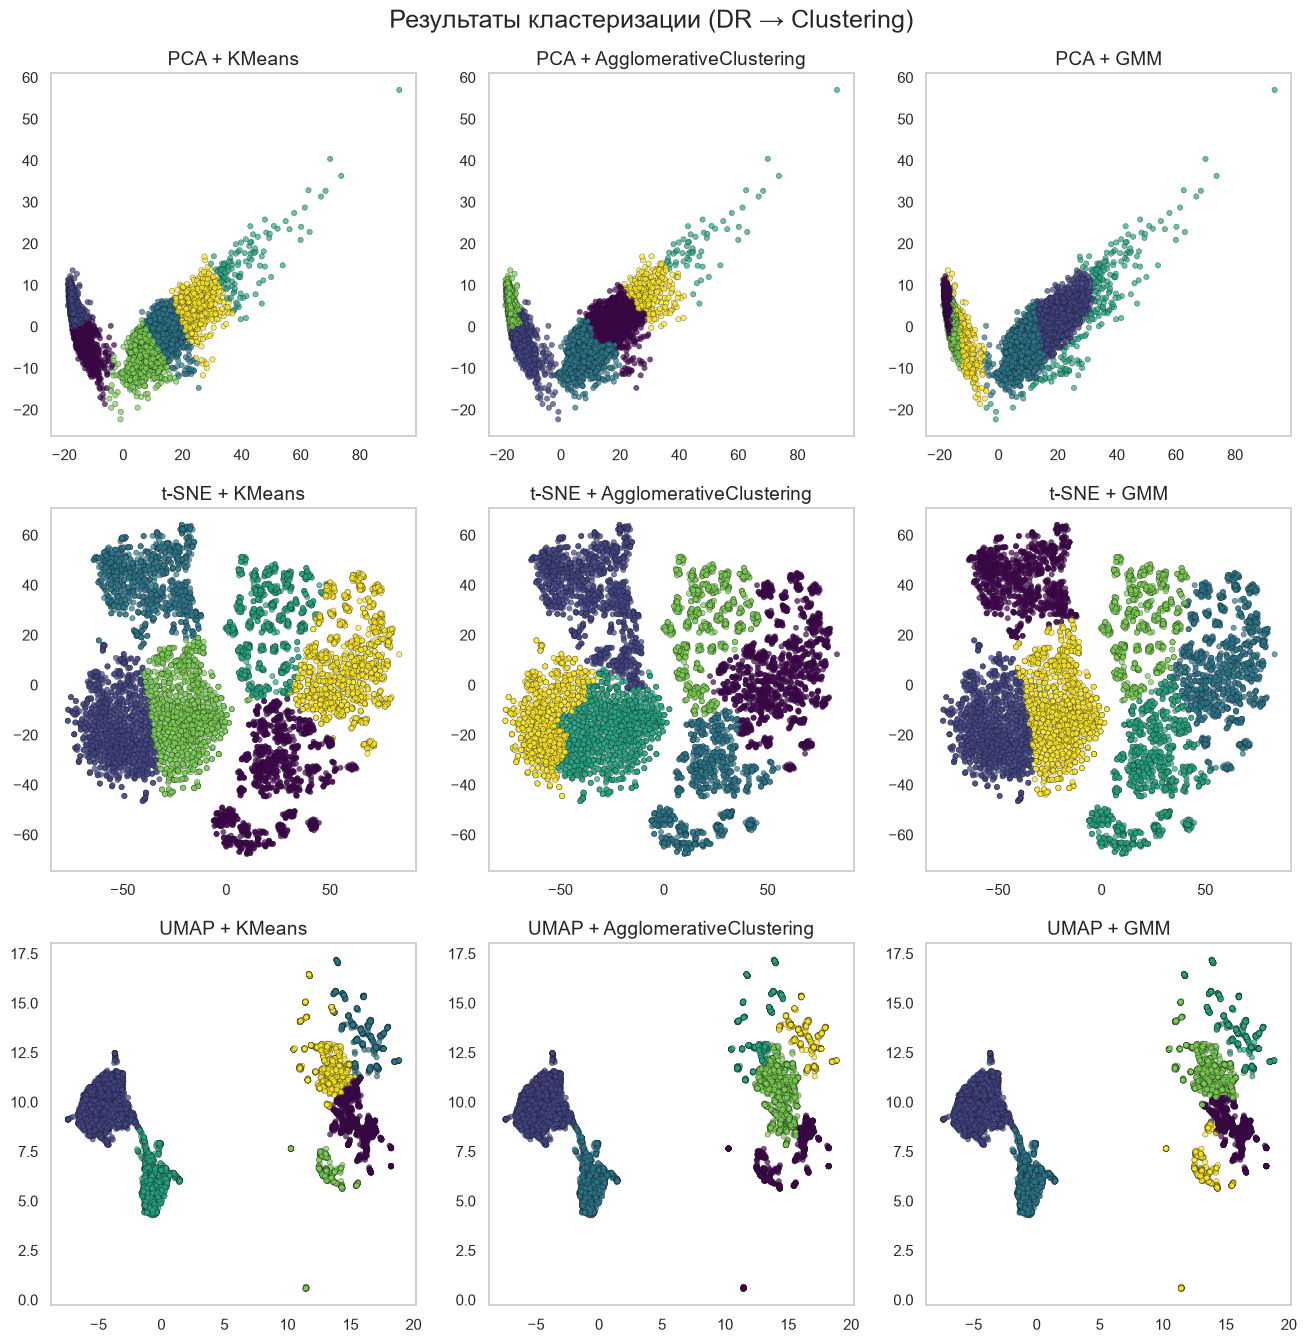

In [32]:
fig, axes = plt.subplots(3, 3, figsize=(16, 16))

decs = ["PCA", "t-SNE", "UMAP"]
algorithms = ["KMeans", "AgglomerativeClustering", "GMM"]

for i, dec in enumerate(decs):
    res1 = res[dec]
    
    for j, cl in enumerate(algorithms):
        ax = axes[i, j]
        labels = all_pred[(dec, cl)]
        
        ax.scatter(res1[:, 0], res1[:, 1], c=labels,
                   cmap="viridis", alpha=0.7, s=15, edgecolors="k", linewidth=0.3)
        
        ax.set_title(f"{dec} + {cl}", fontsize=14)
        ax.grid(False)

plt.suptitle("Результаты кластеризации (DR → Clustering)", fontsize=18, y=0.92)
plt.show()

UMAP создал компактные и четко очерченные «острова»

t-SNE создал «острова», некоторые разбиты на «полуострова», выглядят рваными

PCA разрезал на куски, GMM показал сильное перекрытие кластеров


Оценка устойчивости

In [43]:
def calc_stability(X_st, alg_factory, n_samples=10):
    n_points = len(X_st)
    all_labels = []
    
    for i in range(n_samples):
        ind = np.random.choice(n_points, size=n_points, replace=True)
        X_boot = X_st[ind] 
        
        labels = alg_factory().fit_predict(X_boot)
        
        all_labels.append((ind, labels))
        
    ari = []
    for i in range(n_samples):
        for j in range(i + 1, n_samples):
            idx_i, labels_i = all_labels[i]
            idx_j, labels_j = all_labels[j]
            
            common_ind = np.intersect1d(idx_i, idx_j)
            
            if len(common_ind) > 0:
                dict_i = dict(zip(idx_i, labels_i))
                dict_j = dict(zip(idx_j, labels_j))
                
                common_labels_i = [dict_i[idx] for idx in common_ind]
                common_labels_j = [dict_j[idx] for idx in common_ind]
                
                score = adjusted_rand_score(common_labels_i, common_labels_j)
                ari.append(score)
            
    return np.mean(ari), np.std(ari)

In [51]:
stability_rows = []
for dec, res1 in res.items():
    for alg_name, alg_factory in methods:
        mean_ari, std_ari = calc_stability(res1, alg_factory, n_samples=10)
        stability_rows.append({
            "dec": dec,
            "algorithm": alg_name,
            "stability_mean": round(mean_ari, 4),
            "stability_std": round(std_ari, 4)
        })

stability_df = pd.DataFrame(stability_rows)
stability_df.sort_values("stability_mean", ascending=False)

,dec,algorithm,stability_mean,stability_std
3,t-SNE,KMeans,0.9789,0.0111
6,UMAP,KMeans,0.9562,0.0246
0,PCA,KMeans,0.9096,0.0519
5,t-SNE,GMM,0.8707,0.1296
7,UMAP,AgglomerativeClustering,0.8696,0.0610
2,PCA,GMM,0.7601,0.1352
8,UMAP,GMM,0.7515,0.1250
4,t-SNE,AgglomerativeClustering,0.7050,0.0825
1,PCA,AgglomerativeClustering,0.6821,0.1027


t-SNE + KMeans показал наилучшую устойчивость (0.9789 ± 0.0111)

UMAP + AgglomerativeClustering показал хорошую устойчивость (0.8696 ± 0.0610)

UMAP + GMM показал среднюю устойчивость и высокий разброс (0.7515 ± 0.1250)

Интерпретация

In [35]:
print(f"UMAP + GMM")

best_labels = all_pred[("UMAP", "GMM")]

crosstab = pd.crosstab(
    pd.Series(best_labels, name="Кластер"), 
    pd.Series(y_rnd, name="Активность").map(lambda x: activity_names[x])
)

print("\nМатрица распределения активностей по кластерам:")
crosstab

UMAP + GMM

Матрица распределения активностей по кластерам:


Активность,laying,sitting,standing,walking,walking_downstairs,walking_upstairs
Кластер,,,,,,
0,0,0,0,21,124,682
1,52,989,1000,0,0,0
2,948,8,0,0,0,0
3,0,0,0,655,10,6
4,0,0,0,233,825,19
5,0,3,0,91,41,293


1. Кластер 0 - преимущественно walking_upstairs (подъем по лестнице), но 124 - спуск по лестнице
2. Кластер 1 - смешались sitting (сидение) и standing (стояние)
3. Кластер 2 - почти безошибочно выделил laying (лежание)
4. Кластер 3 - преимущественно выделил walking (ходьба)
5. Кластер 4 - преимущественно walking_downstairs (спуск по лестнице) и 233 - ходьба
6. Кластер 5 - преимущественно walking_upstairs (подъем по лестнице)

UMAP + GMM
* Выделение laying в кластер 2
* Разрыв walking_upstairs на кластеры 0 и 5
* Слияние sitting и standing в кластере 1
* walking в кластере 4 (спуск)

In [45]:
print(f"t-SNE + KMeans")

best_labels = all_pred[("t-SNE", "KMeans")]

crosstab = pd.crosstab(
    pd.Series(best_labels, name="Кластер"), 
    pd.Series(y_rnd, name="Активность").map(lambda x: activity_names[x])
)

print("\nМатрица распределения активностей по кластерам:")
crosstab

t-SNE + KMeans

Матрица распределения активностей по кластерам:


Активность,laying,sitting,standing,walking,walking_downstairs,walking_upstairs
Кластер,,,,,,
0,0,3,0,93,28,954
1,26,564,430,0,0,0
2,960,9,1,0,0,0
3,0,0,0,669,109,18
4,14,424,569,0,2,0
5,0,0,0,238,861,28


1. Кластер 0 - почти безошибочно выделил walking_upstairs (подъем по лестнице)
2. Кластер 1 - смешались sitting (сидение) и standing (стояние)
3. Кластер 2 - почти безошибочно выделил laying (лежание)
4. Кластер 3 - преимущественно выделил walking (ходьба)
5. Кластер 4 - смешались sitting (сидение) и standing (стояние)
6. Кластер 5 - преимущественно walking_downstairs (спуск по лестнице) и 238 ходьба

t-SNE + KMeans
* Слияние sitting и standing в кластере 1, 4
* walking в кластерах 3 и 5 (спуск)
* Выделение laying, walking_upstairs в отдельные кластеры